In [6]:
!pip install transformers torch torchvision pillow matplotlib

In [7]:
%pip install matplotlib numpy jiwer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 26.9 MB/s eta 0:00:00


In [8]:
images = [
    "/content/im3.jpg",
    "/content/im1aa.jpg",
    "/content/a02-012-00.png",
    "/content/im1a.jpg",
    "/content/a02-004-01.png",
    "/content/11.jpg",
    "/content/1.png",
    "/content/b02-035-00.png",
    "/content/b.png",
    "/content/a03-009-00.png"
]

true_texts = [
    "Hi",
    "We are here.",
    "The team is composed of experienced",
    "I am Anjali",
    "the Prime Minister to Paris was dorpped",
    "I am a student at HCMUS",
    "A MOVE to stop Mr. Gaitskell from",
    "On this reading what Mr. Gollanz calls",
    "Otherwise Skip that Column",
    "The wish was particularly apparent in comments"
]


In [9]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from PIL import Image
from jiwer import wer, cer
import matplotlib.pyplot as plt
import numpy as np
import time

processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten")

cer_scores, wer_scores, times = [], [], []

for img_path, truth in zip(images, true_texts):
    image = Image.open(img_path).convert("RGB")

    start = time.time()
    pixel_values = processor(images=image, return_tensors="pt").pixel_values
    generated_ids = model.generate(pixel_values, max_length=256)
    pred_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    end = time.time()

    cer_score = cer(truth, pred_text)
    wer_score = wer(truth, pred_text)
    cer_scores.append(cer_score)
    wer_scores.append(wer_score)
    times.append(end - start)

    print(f"\n Image: {img_path}")
    print(f"True: {truth}")
    print(f"Pred: {pred_text}")
    print(f"CER: {cer_score:.2f}, WER: {wer_score:.2f}, Time: {end-start:.2f}s")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (2 outputs left out)

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


 Image: /content/im3.jpg
True: Hi
Pred: this
CER: 1.50, WER: 1.00, Time: 10.08s

 Image: /content/im1aa.jpg
True: We are here.
Pred: There are never .
CER: 0.67, WER: 1.00, Time: 6.46s

 Image: /content/a02-012-00.png
True: The team is composed of experienced
Pred: The team is composed of experienced
CER: 0.00, WER: 0.00, Time: 7.40s

 Image: /content/im1a.jpg
True: I am Anjali
Pred: " I am Angali ,
CER: 0.45, WER: 1.00, Time: 17.23s

 Image: /content/a02-004-01.png
True: the Prime Minister to Paris was dorpped
Pred: the Prime Minister to Paris was dropped
CER: 0.05, WER: 0.14, Time: 8.02s

 Image: /content/11.jpg
True: I am a student at HCMUS
Pred: I am a student at HCMUS .
CER: 0.09, WER: 0.17, Time: 8.01s

 Image: /content/1.png
True: A MOVE to stop Mr. Gaitskell from
Pred: A MOVE to stop Mr. Gaitskell from
CER: 0.00, WER: 0.00, Time: 10.57s

 Image: /content/b02-035-00.png
True: On this reading what Mr. Gollanz calls
Pred: On this reading what Mr. Gollancz calls
CER: 0.03, WER: 0.

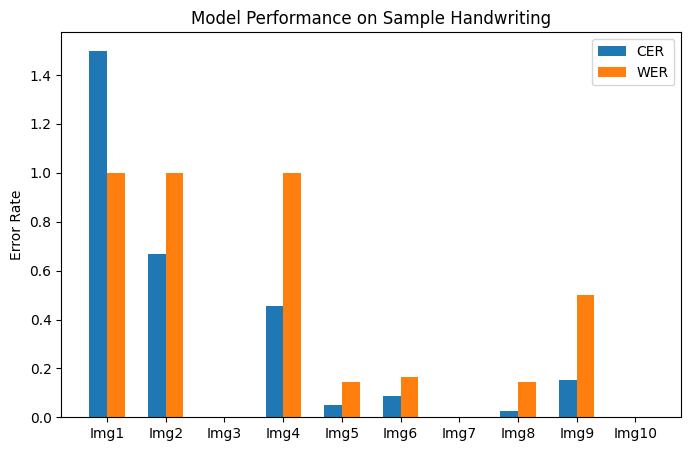

In [10]:
x = np.arange(len(images))
plt.figure(figsize=(8,5))
plt.bar(x - 0.15, cer_scores, width=0.3, label='CER')
plt.bar(x + 0.15, wer_scores, width=0.3, label='WER')
plt.xticks(x, [f"Img{i+1}" for i in range(len(images))])
plt.ylabel("Error Rate")
plt.title("Model Performance on Sample Handwriting")
plt.legend()
plt.show()

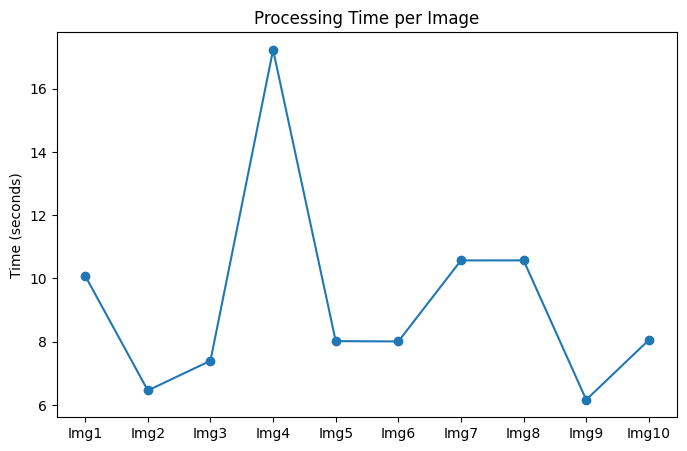

In [11]:
plt.figure(figsize=(8,5))
plt.plot([f"Img{i+1}" for i in range(len(images))], times, marker='o')
plt.ylabel("Time (seconds)")
plt.title("Processing Time per Image")
plt.show()

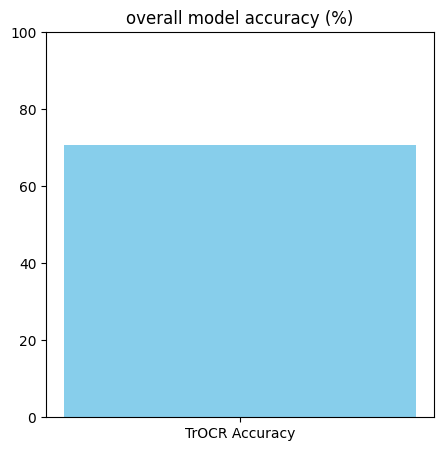


 average character level accuracy: 70.60%


In [12]:
avg_cer = np.mean(cer_scores)
avg_wer = np.mean(wer_scores)
accuracy = (1 - avg_cer) * 100  #roughg acc

plt.figure(figsize=(5,5))
plt.bar(["TrOCR Accuracy"], [accuracy], color='skyblue')
plt.ylim(0,100)
plt.title("overall model accuracy (%)")
plt.show()

print(f"\n average character level accuracy: {accuracy:.2f}%")


In [13]:
save_directory = "./trocr_handwritten_model"
model.save_pretrained(save_directory)

processor.save_pretrained(save_directory)


[]

In [1]:
#individual

In [ ]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from PIL import Image
import torch

In [ ]:
processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten")

image = Image.open("/content/out2.png").convert("RGB")

#preprocesing
pixel_values = processor(images=image, return_tensors="pt").pixel_values

generated_ids = model.generate(pixel_values, max_length=256)
generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print("Recognized Text:\n", generated_text)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['enco

Recognized Text:
 I am a student at HCMUS .


In [ ]:
processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten")

image = Image.open("/content/11.jpg").convert("RGB")
pixel_values = processor(images=image, return_tensors="pt").pixel_values

generated_ids = model.generate(pixel_values, max_length=256)
generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print("Recognized Text:\n", generated_text)

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Recognized Text:
 I am a student at HCMUS .


In [15]:
processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten")

image = Image.open("/content/1.png").convert("RGB")
pixel_values = processor(images=image, return_tensors="pt").pixel_values

generated_ids = model.generate(pixel_values, max_length=256)
generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print("Recognized Text:\n", generated_text)

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Recognized Text:
 A MOVE to stop Mr. Gaitskell from


In [ ]:
image = Image.open("/content/a02-004-01.png").convert("RGB")
pixel_values = processor(images=image, return_tensors="pt").pixel_values

generated_ids = model.generate(pixel_values, max_length=256)
generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print("Recognized Text:\n", generated_text)

Recognized Text:
 the Prime Minister to Paris was dropped


In [ ]:
image = Image.open("/content/a03-009-00.png").convert("RGB")
pixel_values = processor(images=image, return_tensors="pt").pixel_values

generated_ids = model.generate(pixel_values, max_length=256)
generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print("Recognized Text:\n", generated_text)

Recognized Text:
 The wish was particularly apparent in comments


In [ ]:
image = Image.open("/content/b.png").convert("RGB")
pixel_values = processor(images=image, return_tensors="pt").pixel_values

generated_ids = model.generate(pixel_values, max_length=256)
generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print("Recognized Text:\n", generated_text)

Recognized Text:
 Otherwise Skip that Column . "


In [27]:
!pip install gradio


In [28]:
import gradio as gr
from PIL import Image
from transformers import TrOCRProcessor, VisionEncoderDecoderModel


In [29]:
save_directory = "./trocr_handwritten_model"
processor = TrOCRProcessor.from_pretrained(save_directory)
model = VisionEncoderDecoderModel.from_pretrained(save_directory)

In [30]:
def predict_text(image):
    image = image.convert("RGB")
    pixel_values = processor(images=image, return_tensors="pt").pixel_values
    generated_ids = model.generate(pixel_values, max_length=256)
    pred_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return pred_text

In [31]:
iface = gr.Interface(
    fn=predict_text,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="Handwritten Text Recognition",
    description="Upload a handwritten image and get the predicted text."
)

In [32]:
iface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://57ded84a1bd28d614b.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
